<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

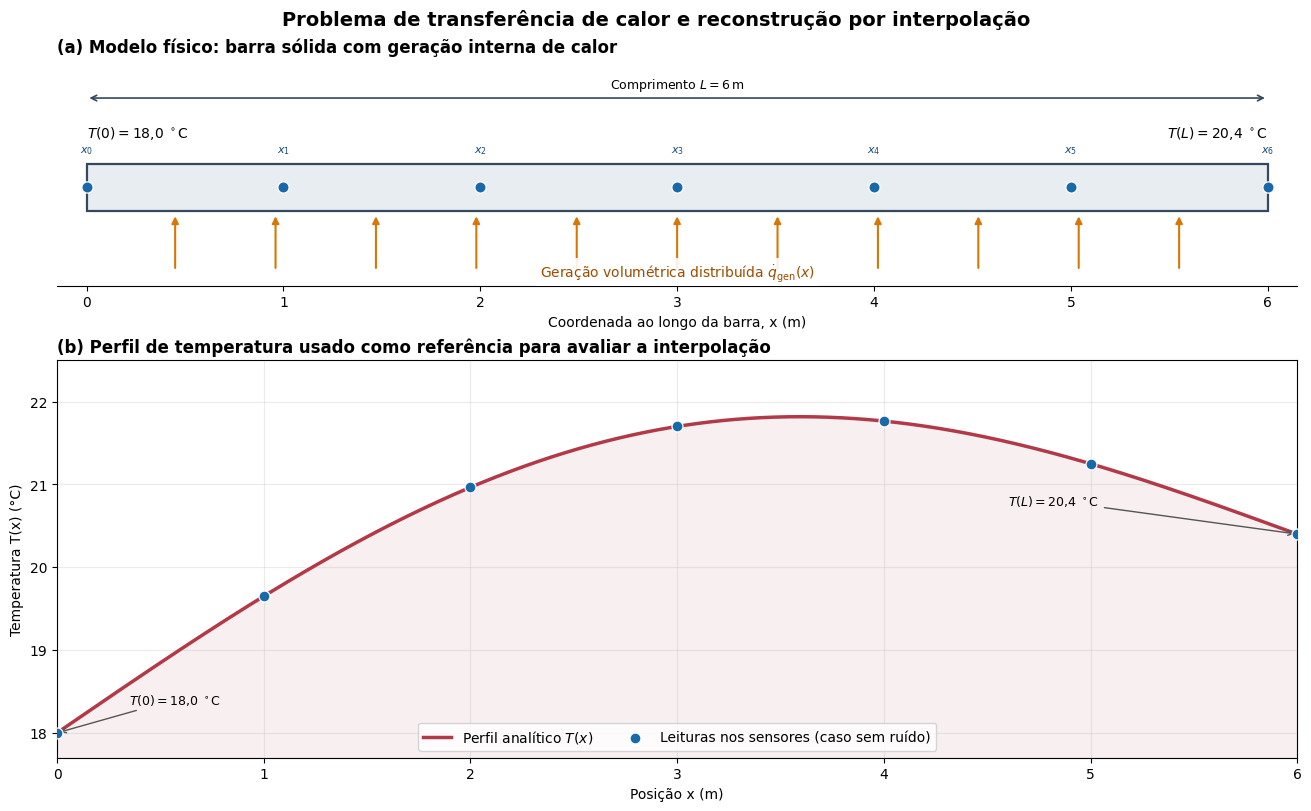

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


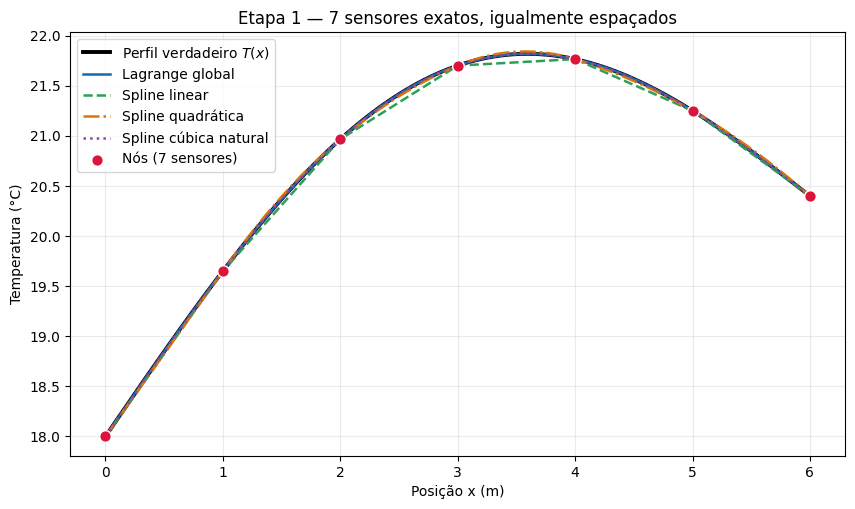

In [4]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# 1-4) Métricas na malha fina (pontos ENTRE os nós, não só nos nós)
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# 5a) Temperaturas: os quatro métodos sobrepostos à função verdadeira
estilos = {"Lagrange global":       dict(color="#1769aa", ls="-"),
           "Spline linear":         dict(color="#2e9e5b", ls="--"),
           "Spline quadrática":     dict(color="#d97706", ls="-."),
           "Spline cúbica natural": dict(color="#8e44ad", ls=":")}

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x_fino, T_fino, color="k", lw=2.8, label="Perfil verdadeiro $T(x)$", zorder=1)
for nome, metodo in metodos_7.items():
    ax.plot(x_fino, metodo(x_fino), lw=1.8, label=nome, **estilos[nome])
ax.scatter(x_nos_7, y_nos_7, s=70, c="crimson", edgecolor="white", zorder=5, label="Nós (7 sensores)")
ax.set_xlabel("Posição x (m)"); ax.set_ylabel("Temperatura (°C)")
ax.set_title("Etapa 1 — 7 sensores exatos, igualmente espaçados")
ax.grid(alpha=0.25); ax.legend(); plt.show()


### Observações — Etapa 1 (7 sensores exatos, equiespaçados)

**Ordem dos erros (menor → maior):** Lagrange global ($E_{max}\approx 8{,}5\times10^{-5}$ °C, RMSE $\approx 3{,}3\times10^{-5}$ °C) < spline cúbica natural ($5{,}1\times10^{-4}$ / $2{,}4\times10^{-4}$) < spline quadrática ($2{,}4\times10^{-2}$ / $1{,}6\times10^{-2}$) < spline linear ($8{,}2\times10^{-2}$ / $4{,}4\times10^{-2}$).

**Por que essa ordem?** O perfil $T(x)=18+2{,}4\,\xi+2{,}5\sin(\pi\xi)$ é analítico (infinitamente derivável, com derivadas limitadas). Quanto mais "graus de liberdade suaves" o método usa, melhor ele captura a curvatura:

- **Linear:** o erro de interpolação é $\approx \frac{h^2}{8}\max|T''|$. Com $h=1$ m e $\max|T''|=2{,}5\pi^2/36\approx0{,}69$ °C/m², isso dá $\approx0{,}086$ °C — coerente com o $E_{max}=0{,}082$ °C medido.
- **Lagrange (grau 6):** o erro é $\frac{T^{(7)}(\xi)}{7!}\prod_i(x-x_i)$. Como $|T^{(7)}|\le 2{,}5(\pi/6)^7\approx0{,}027$, a cota fica em $\approx5\times10^{-4}$ °C, e o erro medido ($8{,}5\times10^{-5}$ °C) está abaixo dela.
- **Splines:** são locais; cada grau a mais (linear → quadrática → cúbica) reduz o erro em cerca de uma ordem de grandeza.

**Onde o erro aparece?** Nos nós o erro é ~0 (os métodos reproduzem os sensores); o erro máximo ocorre **entre** os nós, e por isso a avaliação foi feita na malha fina de 2001 pontos. Os painéis de erro assinado mostram que o erro do Lagrange é pequeno no centro e maior perto das extremidades.

**Cuidado:** esse "Lagrange vence" vale para este perfil suave com dados exatos e $N=7$; não é um resultado geral (veja as Etapas 2 e 3).


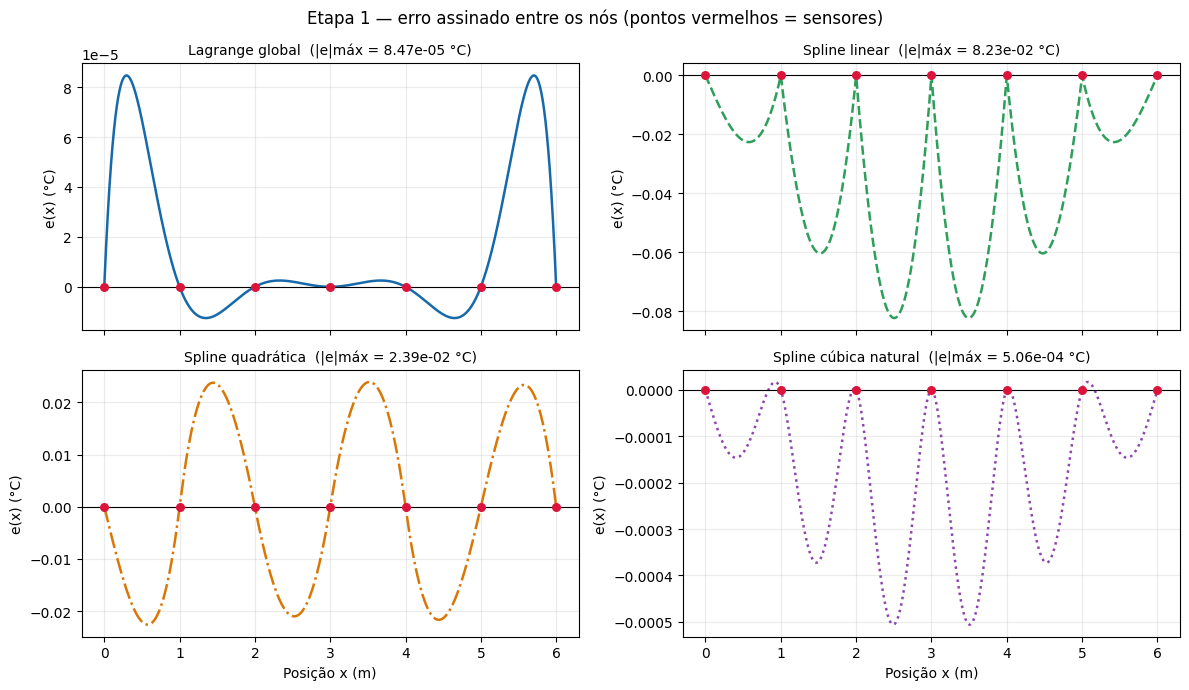

In [5]:
# Erros assinados e(x) = metodo(x_fino) - T_fino, um painel por método
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (nome, metodo) in zip(axs.ravel(), metodos_7.items()):
    erro = np.asarray(metodo(x_fino)) - T_fino
    ax.plot(x_fino, erro, lw=1.8, **estilos[nome])
    ax.axhline(0, color="k", lw=0.8)
    ax.scatter(x_nos_7, np.zeros_like(x_nos_7), c="crimson", s=30, zorder=5)  # nós: erro ~ 0
    ax.set_title(f"{nome}  (|e|máx = {np.max(np.abs(erro)):.2e} °C)", fontsize=10)
    ax.set_ylabel("e(x) (°C)"); ax.grid(alpha=0.25)
for ax in axs[1]: ax.set_xlabel("Posição x (m)")
fig.suptitle("Etapa 1 — erro assinado entre os nós (pontos vermelhos = sensores)", fontsize=12)
plt.tight_layout(); plt.show()


## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

,N,Nós,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçados,4.53e-03,2.16e-03
1,5,Chebyshev,2.33e-03,1.53e-03
2,9,Equiespaçados,1.04e-06,3.44e-07
3,9,Chebyshev,2.17e-07,1.20e-07
4,13,Equiespaçados,5.91e-11,1.55e-11
5,13,Chebyshev,3.62e-12,1.93e-12
6,17,Equiespaçados,1.99e-12,2.45e-13
7,17,Chebyshev,1.42e-14,3.80e-15


Razão Emax(equiespaçado)/Emax(Chebyshev):
N
5       1.9
9       4.8
13     16.3
17    140.0


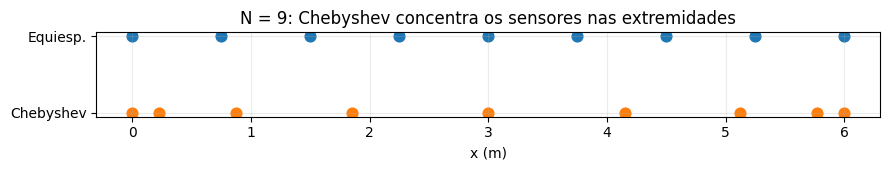

In [6]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

def erros_lagrange(x_nos):
    """Emax e RMSE do Lagrange global com sensores exatos em x_nos, avaliado na malha fina."""
    p = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
    e = p(x_fino) - T_fino
    return np.max(np.abs(e)), np.sqrt(np.mean(e**2))

linhas = []
for N in [5, 9, 13, 17]:
    for rotulo, x_nos in [("Equiespaçados", np.linspace(x_min, x_max, N)),
                          ("Chebyshev",     nos_chebyshev_lobatto(x_min, x_max, N))]:
        emax, rmse = erros_lagrange(x_nos)
        linhas.append({"N": N, "Nós": rotulo, "Erro máximo (°C)": emax, "RMSE (°C)": rmse})

tabela_nos = pd.DataFrame(linhas)
display(tabela_nos.style.format({"Erro máximo (°C)": "{:.2e}", "RMSE (°C)": "{:.2e}"}))

# Razão equiespaçado / Chebyshev (>1 => Chebyshev é melhor)
piv = tabela_nos.pivot(index="N", columns="Nós", values="Erro máximo (°C)")
print("Razão Emax(equiespaçado)/Emax(Chebyshev):")
print((piv["Equiespaçados"]/piv["Chebyshev"]).round(1).to_string())

# Posição dos nós para N = 9
fig, ax = plt.subplots(figsize=(9, 1.8))
ax.scatter(np.linspace(x_min, x_max, 9), np.ones(9),  s=60, label="Equiespaçados")
ax.scatter(nos_chebyshev_lobatto(x_min, x_max, 9), np.zeros(9), s=60, label="Chebyshev-Lobatto")
ax.set_yticks([0, 1]); ax.set_yticklabels(["Chebyshev", "Equiesp."]); ax.set_xlabel("x (m)")
ax.set_title("N = 9: Chebyshev concentra os sensores nas extremidades"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()


### Observações — Etapa 2 (nós equiespaçados × Chebyshev-Lobatto, Lagrange global)

| N | $E_{max}$ equiesp. | $E_{max}$ Chebyshev | razão |
|---|---|---|---|
| 5 | $4{,}5\times10^{-3}$ | $2{,}3\times10^{-3}$ | ≈ 1,9 |
| 9 | $1{,}0\times10^{-6}$ | $2{,}2\times10^{-7}$ | ≈ 4,8 |
| 13 | $5{,}9\times10^{-11}$ | $3{,}6\times10^{-12}$ | ≈ 16 |
| 17 | $2{,}0\times10^{-12}$ | $\sim10^{-14}$ | > 100 |

- Para os quatro valores de $N$, **Chebyshev tem menor $E_{max}$ e menor RMSE**, e a vantagem cresce com $N$.
- Nos equiespaçados, o erro se concentra **perto das extremidades** (para $N=9$ o maior erro está em $x\approx0{,}2$ m, e o erro nas bordas é ~50 vezes o do terço central). Isso acontece porque o polinômio nodal $\prod(x-x_i)$ é muito maior nas bordas quando os nós são equiespaçados; Chebyshev concentra nós nas bordas e deixa esse fator quase uniforme.
- Com $N=17$ o Lagrange-Chebyshev chega ao **piso de arredondamento** ($\sim10^{-14}$ °C, da ordem de $\varepsilon_{máq}\times|T|$): não dá para melhorar mais.

**Relação com a suavidade do perfil.** Aqui nenhuma das duas distribuições "explode" para $N\le17$, porque $T$ é analítica e suas derivadas decaem rápido ($|T^{(n)}|\le2{,}5(\pi/L)^n$): o termo $T^{(N)}/N!$ do erro cai mais rápido do que o polinômio nodal cresce. O fenômeno de Runge aparece com funções menos amigáveis (por exemplo, $1/(1+25x^2)$) — então **a vantagem observada aqui não prova que valha para qualquer função**, e o ganho de Chebyshev neste caso é, em termos absolutos, pequeno (os erros já são minúsculos). Ele só se torna decisivo quando $N$ cresce (Etapa 3) ou o perfil é menos regular.


## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

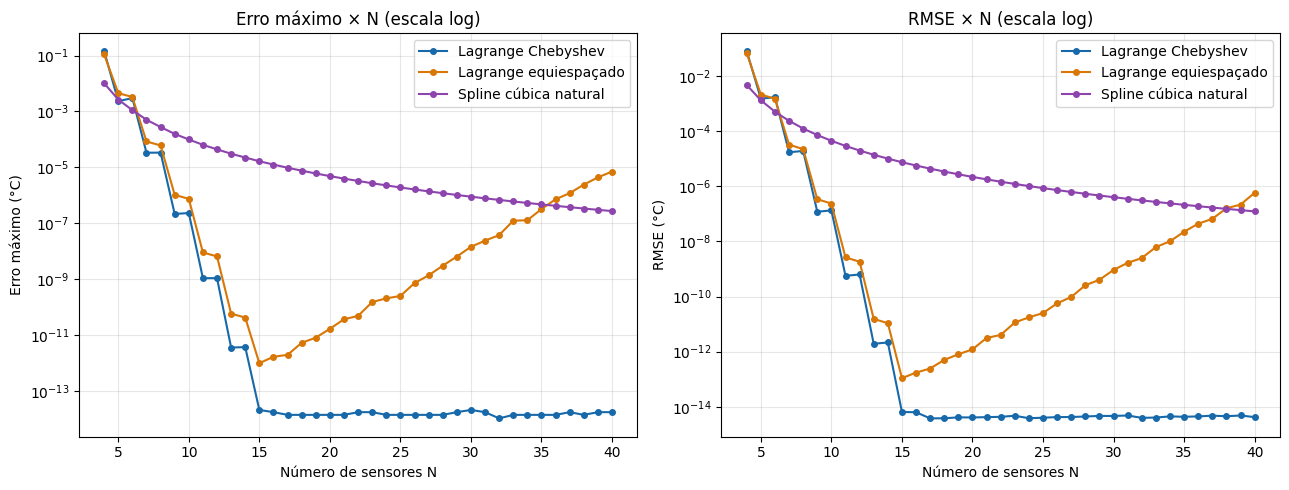

Erro máximo (°C) para N selecionados:


Método,Lagrange Chebyshev,Lagrange equiespaçado,Spline cúbica natural
N,,,
4,1.4e-01,1.1e-01,1.0e-02
5,2.3e-03,4.5e-03,2.7e-03
6,3.0e-03,3.3e-03,1.1e-03
7,3.4e-05,8.5e-05,5.1e-04
9,2.2e-07,1.0e-06,1.6e-04
13,3.6e-12,5.9e-11,3.1e-05
17,1.4e-14,2.0e-12,9.7e-06
25,1.4e-14,2.5e-10,1.9e-06
33,1.4e-14,1.2e-07,6.1e-07


Método com menor Emax, por faixa de N:
  Lagrange Chebyshev: N = [5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
  Spline cúbica natural: N = [4, 6]
A spline cúbica passa a ganhar do Lagrange equiespaçado de forma definitiva a partir de N = 36
Ordem de convergência observada da spline (N >= 20): O(h^4.01)

Tempos médios (ms) sobre N = 4..40:


,t_construção (ms),t_avaliação (ms)
Método,,
Lagrange Chebyshev,0.0934,0.2468
Lagrange equiespaçado,0.0946,0.2489
Spline cúbica natural,0.0908,0.0203


In [7]:
import time

def melhor_tempo(fun, repeticoes=7):
    """Menor tempo (s) em 'repeticoes' execuções: reduz o ruído de medição do tempo."""
    melhor = np.inf
    for _ in range(repeticoes):
        t0 = time.perf_counter(); resultado = fun(); melhor = min(melhor, time.perf_counter()-t0)
    return melhor, resultado

construtores = {
    "Lagrange equiespaçado": (lambda N: np.linspace(x_min, x_max, N),
                              lambda x, y: BarycentricInterpolator(x, y)),
    "Lagrange Chebyshev":    (lambda N: nos_chebyshev_lobatto(x_min, x_max, N),
                              lambda x, y: BarycentricInterpolator(x, y)),
    "Spline cúbica natural": (lambda N: np.linspace(x_min, x_max, N),
                              lambda x, y: CubicSpline(x, y, bc_type="natural")),
}

registros = []
for N in range(4, 41):
    for nome, (gera_nos, constroi) in construtores.items():
        x_nos = gera_nos(N); y_nos = temperatura_real(x_nos)
        t_cons, f = melhor_tempo(lambda: constroi(x_nos, y_nos))
        t_aval, p = melhor_tempo(lambda: f(x_fino))
        e = p - T_fino
        registros.append({"N": N, "Método": nome,
                          "Emax": np.max(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)),
                          "t_construção (ms)": 1e3*t_cons, "t_avaliação (ms)": 1e3*t_aval})
res = pd.DataFrame(registros)

cores = {"Lagrange equiespaçado": "#d97706", "Lagrange Chebyshev": "#1769aa", "Spline cúbica natural": "#8e44ad"}
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, tit in zip(axs, ["Emax", "RMSE"], ["Erro máximo", "RMSE"]):
    for nome, g in res.groupby("Método"):
        ax.semilogy(g["N"], np.maximum(g[col], 1e-17), "o-", ms=4, color=cores[nome], label=nome)
    ax.set_xlabel("Número de sensores N"); ax.set_ylabel(f"{tit} (°C)")
    ax.set_title(f"{tit} × N (escala log)"); ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

sel = [4, 5, 6, 7, 9, 13, 17, 25, 33, 40]
tab = res[res["N"].isin(sel)].pivot(index="N", columns="Método", values="Emax")
print("Erro máximo (°C) para N selecionados:")
display(tab.style.format("{:.1e}"))

print("Método com menor Emax, por faixa de N:")
melhor = res.loc[res.groupby("N")["Emax"].idxmin(), ["N", "Método"]]
for nome, g in melhor.groupby("Método"):
    print(f"  {nome}: N = {list(g['N'])}")

p = res.pivot(index="N", columns="Método", values="Emax")
ganha = p["Spline cúbica natural"] < p["Lagrange equiespaçado"]
N0 = next(N for N in p.index if ganha.loc[N:].all())
print(f"A spline cúbica passa a ganhar do Lagrange equiespaçado de forma definitiva a partir de N = {N0}")

# ordem de convergência observada da spline (inclinação em log-log, h = L/(N-1))
g = res[res["Método"] == "Spline cúbica natural"].set_index("N")["Emax"]
ordem = np.polyfit(np.log(L/(g.index[g.index >= 20]-1)), np.log(g[g.index >= 20]), 1)[0]
print(f"Ordem de convergência observada da spline (N >= 20): O(h^{ordem:.2f})")

print("\nTempos médios (ms) sobre N = 4..40:")
display(res.groupby("Método")[["t_construção (ms)", "t_avaliação (ms)"]].mean().round(4))


### Discussão — Etapa 3 ($N=4$ a $40$)

**O que os gráficos mostram**

- **Lagrange com Chebyshev:** o erro cai geometricamente e atinge o piso de arredondamento ($\sim10^{-14}$ °C) em $N\approx15$–$17$, permanecendo aí até $N=40$ — comportamento estável.
- **Lagrange equiespaçado:** o erro cai até $N\approx16$ ($\sim10^{-12}$ °C) e depois **volta a crescer**: $\sim10^{-11}$ (N=20), $\sim10^{-8}$ (N=30) e $\sim10^{-5}$ °C (N=40). Esse crescimento não é erro de truncamento (que continuaria caindo): é **amplificação de erros de arredondamento** pela constante de Lebesgue, que cresce exponencialmente ($\sim2^N$) para nós equiespaçados. A forma baricêntrica melhora a avaliação, mas não corrige o mau condicionamento da escolha dos nós.
- **Spline cúbica natural:** o erro decresce de modo regular e **sem piso nem reversão** até $N=40$; a inclinação em escala log-log dá ordem observada $O(h^{4})$. Isso é mais do que se espera de uma spline natural em geral ($O(h^2)$ perto das bordas) e se explica pela estrutura do perfil: como $T''\propto\sin(\pi x/L)$, temos $T''(0)=T''(L)=0$, e a condição "natural" coincide com o comportamento real do perfil. Com um perfil em que $T''\neq0$ nas bordas, a spline natural perderia essa ordem.

**Há um único método superior para todo $N$? Não.** Neste experimento (dados exatos):

- $N=4$ e $N=6$: a **spline cúbica** tem o menor $E_{max}$ (para $N=4$, $1{,}0\times10^{-2}$ contra $\approx1{,}1\times10^{-1}$ °C do Lagrange equiespaçado);
- $N=5$ e $N\ge7$: o **Lagrange-Chebyshev** é o melhor, por muitas ordens de grandeza;
- contra o **Lagrange equiespaçado**, a spline cúbica passa a ser melhor de forma definitiva em $N\approx35$ (o valor exato oscila um pouco entre execuções, pois ali o erro do Lagrange é dominado por arredondamento).

O vencedor depende de $N$, da distribuição dos nós e do critério (erro, estabilidade, custo, robustez a ruído).

**Custo e estabilidade**

- *Custo:* para $N\le40$, tudo leva frações de milissegundo; as diferenças de tempo não decidem nada. Em ordem de grandeza, a avaliação do Lagrange baricêntrico custa $O(N)$ por ponto, enquanto a da spline custa $O(\log N)$ (busca do intervalo); por isso, aqui, a avaliação da spline foi cerca de 10× mais rápida, e a construção das splines (sistema tridiagonal, $O(N)$) é comparável à do Lagrange. Os tempos exatos dependem da máquina.
- *Estabilidade:* Lagrange equiespaçado com $N$ grande é instável; Lagrange-Chebyshev e a spline são estáveis. Além disso, a spline é **local** (um dado ruim afeta poucos intervalos) e o Lagrange é **global** (um dado ruim afeta todo o intervalo).


## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

Ruído gaussiano com σ = 0.1 °C — média de 300 sorteios


Método,Ajuste poli. grau 4 (MQ),Lagrange Chebyshev,Lagrange equiespaçado,Spline cúbica natural
N,,,,
7,0.0706,0.0942,0.117,0.0893
13,0.0527,0.0961,0.741,0.0923
21,0.0428,0.0982,65.1,0.0923
31,0.0367,0.0994,2.52e+04,0.0926


Método,Ajuste poli. grau 4 (MQ),Lagrange Chebyshev,Lagrange equiespaçado,Spline cúbica natural
N,,,,
7,0.14,0.185,0.254,0.184
13,0.119,0.215,3.12,0.208
21,0.106,0.239,367,0.228
31,0.0936,0.258,1.78e+05,0.242


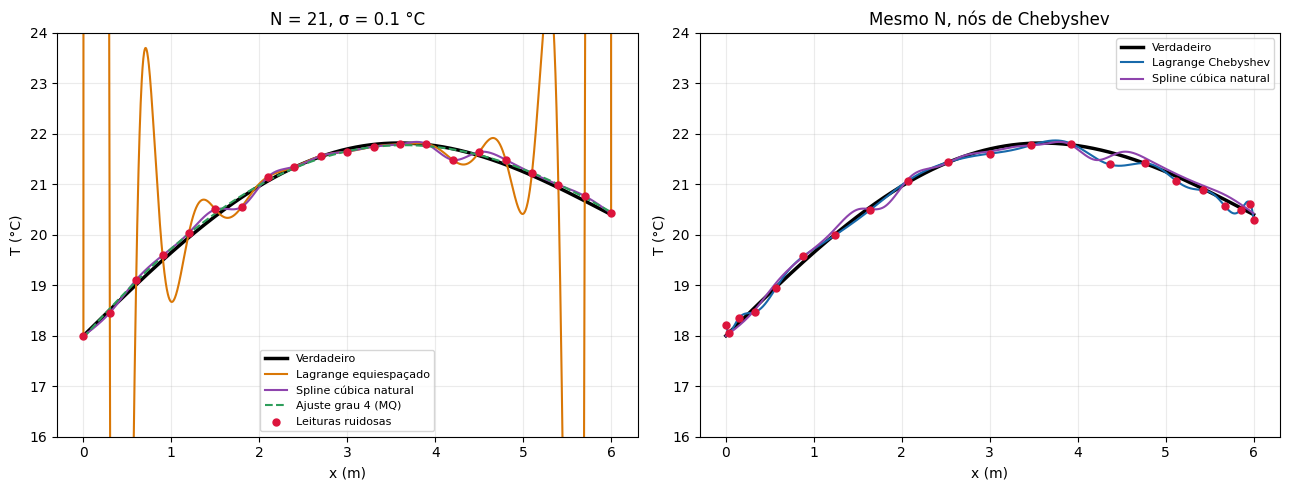

,x (m),"dentro de [0, 6]?",|erro| Lagrange (°C),|erro| spline natural (°C)
0,3.5,True,2.06e-06,5.06e-04
1,5.5,True,6.68e-05,1.36e-04
2,6.0,True,0.00e+00,0.00e+00
3,6.5,False,1.19e-03,1.36e-04
4,7.5,False,2.25e-02,2.33e-03
5,9.0,False,3.28e-01,1.52e-01


In [8]:
# ---------- Experimentos de apoio à Etapa 4 ----------
rng = np.random.default_rng(42)       # semente fixa: resultados reproduzíveis
sigma = 0.10                          # desvio-padrão do ruído do sensor (°C), hipótese do estudo

def mc_ruido(constroi, x_nos, n_rep=300):
    """Média, em n_rep sorteios de ruído, de Emax e RMSE contra a verdade, na malha fina."""
    E, R = [], []
    for _ in range(n_rep):
        y = temperatura_real(x_nos) + rng.normal(0, sigma, len(x_nos))
        e = constroi(x_nos, y)(x_fino) - T_fino
        E.append(np.max(np.abs(e))); R.append(np.sqrt(np.mean(e**2)))
    return np.mean(E), np.mean(R)

lag = lambda x, y: BarycentricInterpolator(x, y)
spl = lambda x, y: CubicSpline(x, y, bc_type="natural")
ajuste4 = lambda x, y: np.poly1d(np.polyfit(x, y, 4))      # NÃO interpola: mínimos quadrados, grau 4

linhas = []
for N in [7, 13, 21, 31]:
    xe = np.linspace(x_min, x_max, N); xc = nos_chebyshev_lobatto(x_min, x_max, N)
    for nome, c, x in [("Lagrange equiespaçado", lag, xe), ("Lagrange Chebyshev", lag, xc),
                       ("Spline cúbica natural", spl, xe), ("Ajuste poli. grau 4 (MQ)", ajuste4, xe)]:
        emax, rmse = mc_ruido(c, x)
        linhas.append({"N": N, "Método": nome, "Emax médio (°C)": emax, "RMSE médio (°C)": rmse})
tab_ruido = pd.DataFrame(linhas)
print(f"Ruído gaussiano com σ = {sigma} °C — média de 300 sorteios")
display(tab_ruido.pivot(index="N", columns="Método", values="RMSE médio (°C)").style.format("{:.3g}"))
display(tab_ruido.pivot(index="N", columns="Método", values="Emax médio (°C)").style.format("{:.3g}"))

# Uma realização com N = 21 sensores ruidosos
N = 21
xe = np.linspace(x_min, x_max, N); xc = nos_chebyshev_lobatto(x_min, x_max, N)
ye = temperatura_real(xe) + rng.normal(0, sigma, N); yc = temperatura_real(xc) + rng.normal(0, sigma, N)
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
axs[0].plot(x_fino, T_fino, "k", lw=2.5, label="Verdadeiro")
axs[0].plot(x_fino, lag(xe, ye)(x_fino), color="#d97706", label="Lagrange equiespaçado")
axs[0].plot(x_fino, spl(xe, ye)(x_fino), color="#8e44ad", label="Spline cúbica natural")
axs[0].plot(x_fino, ajuste4(xe, ye)(x_fino), color="#2e9e5b", ls="--", label="Ajuste grau 4 (MQ)")
axs[0].scatter(xe, ye, c="crimson", s=25, zorder=5, label="Leituras ruidosas")
axs[0].set_ylim(16, 24); axs[0].set_title(f"N = {N}, σ = {sigma} °C"); axs[0].legend(fontsize=8)
axs[1].plot(x_fino, T_fino, "k", lw=2.5, label="Verdadeiro")
axs[1].plot(x_fino, lag(xc, yc)(x_fino), color="#1769aa", label="Lagrange Chebyshev")
axs[1].plot(x_fino, spl(xe, ye)(x_fino), color="#8e44ad", label="Spline cúbica natural")
axs[1].scatter(xc, yc, c="crimson", s=25, zorder=5)
axs[1].set_ylim(16, 24); axs[1].set_title("Mesmo N, nós de Chebyshev"); axs[1].legend(fontsize=8)
for ax in axs: ax.set_xlabel("x (m)"); ax.set_ylabel("T (°C)"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

# ---------- Interpolação × extrapolação (dados exatos, 7 sensores em [0, 6]) ----------
xe7 = np.linspace(x_min, x_max, 7); ye7 = temperatura_real(xe7)
f_lag = BarycentricInterpolator(xe7, ye7)
f_spl = CubicSpline(xe7, ye7, bc_type="natural", extrapolate=True)
xt = np.array([3.5, 5.5, 6.0, 6.5, 7.5, 9.0])   # 3.5 e 5.5: entre nós; 6.0: borda; >6: extrapolação
tab_ext = pd.DataFrame({"x (m)": xt, "dentro de [0, 6]?": xt <= L,
                        "|erro| Lagrange (°C)": np.abs(f_lag(xt) - temperatura_real(xt)),
                        "|erro| spline natural (°C)": np.abs(f_spl(xt) - temperatura_real(xt))})
display(tab_ext.style.format({"x (m)": "{:.1f}", "|erro| Lagrange (°C)": "{:.2e}", "|erro| spline natural (°C)": "{:.2e}"}))


### Recomendação técnica — Etapa 4

Métricas usadas: **erro máximo** ($E_{max}$) e **RMSE**, nas Etapas 1–3 e nas simulações com ruído acima (ruído gaussiano com $\sigma=0{,}1$ °C, 300 sorteios por caso; valor de $\sigma$ adotado como hipótese).

**1. Poucos sensores exatos.** Com $N=4$, a **spline cúbica natural** é a escolha: $E_{max}=1{,}0\times10^{-2}$ °C contra $1{,}1\times10^{-1}$ °C (Lagrange equiespaçado) — uma ordem de grandeza menor. Com 5 a 7 sensores, ambos ficam abaixo de $5\times10^{-3}$ °C neste perfil; eu ainda preferiria a spline quando não se tem certeza de que o perfil é suave, porque ela é local e seu erro não depende de hipóteses sobre derivadas de alta ordem. O Lagrange só é vantajoso se houver confiança na suavidade global do perfil.

**2. Mais sensores.** Se for possível escolher as posições, usar **Lagrange com nós de Chebyshev**: o erro chega a $\sim10^{-14}$ °C a partir de $N\approx17$. Se as posições forem fixas e uniformes, usar a **spline cúbica** (erro $\propto h^4$ e estável); **evitar Lagrange equiespaçado com $N$ grande** (acima de $N\approx16$ o erro piora, e com ruído é desastroso).

**3. Sensores ruidosos.** A interpolação passa por cada leitura, logo **reproduz o ruído**: com $\sigma=0{,}1$ °C, o RMSE da spline e do Lagrange-Chebyshev fica em $\approx0{,}09$–$0{,}10$ °C **independentemente de $N$** (spline: 0,089 → 0,093 de $N=7$ a $31$) — mais sensores não reduzem o erro. Pior: no Lagrange equiespaçado o ruído é amplificado pela constante de Lebesgue (RMSE $\approx0{,}74$ °C com $N=13$, $\approx65$ °C com $N=21$ e $\approx2\times10^{4}$ °C com $N=31$). Com ruído, a recomendação é **não interpolar, e sim suavizar**: um ajuste por mínimos quadrados de grau baixo (aqui, grau 4) deu RMSE de $0{,}071$ °C ($N=7$) a $0{,}037$ °C ($N=31$), **abaixo de $\sigma$ e melhorando com $N$**, porque faz a média do ruído entre os sensores. O grau (ou o parâmetro de suavização, no caso de uma spline suavizante) deve ser escolhido por validação cruzada, e não fixado de antemão como fiz aqui por conhecer o perfil.

**4. Extremidades.** (a) Colocar sensores nas bordas (ou usar as temperaturas prescritas $T(0)$, $T(L)$ como dados exatos); (b) com Lagrange, usar nós de Chebyshev, que adensam os sensores nas bordas, onde o erro é maior; (c) a condição "natural" ($T''=0$) é correta neste perfil, mas é uma **hipótese**: se houver geração de calor nas bordas ($T''\neq0$), usar *not-a-knot* ou impor a derivada, sob pena de perder a ordem de convergência perto das extremidades.

**5. Interpolação × extrapolação.** Todas as conclusões acima valem **dentro** de $[x_{min},x_{max}]$ coberto pelos sensores. Fora dele os erros crescem rapidamente (7 sensores, dados exatos): em $x=6{,}5$ m, $1{,}2\times10^{-3}$ °C (Lagrange) e $1{,}4\times10^{-4}$ °C (spline); em $x=7{,}5$ m, $2{,}2\times10^{-2}$ e $2{,}3\times10^{-3}$ °C; em $x=9$ m, $0{,}33$ e $0{,}15$ °C — e isso para um perfil suave e sem ruído. Não se deve extrapolar; se for necessário, usar o modelo físico, não a interpolação.

**6. Limitações quando a temperatura verdadeira é desconhecida.** Em campo não se pode calcular $E_{max}$ nem RMSE contra $T(x)$; só há estimativas indiretas (validação cruzada *leave-one-out*, sensores reservados para teste, comparação entre métodos, análise de resíduos). Também permanecem: $\sigma$ desconhecido e talvez não gaussiano nem constante; erro sistemático/calibração dos sensores; incerteza na posição dos sensores; perfis menos suaves que o aqui usado (por exemplo, uma fonte concentrada), em que os erros serão maiores e a escolha do método pode mudar; e a validade do próprio modelo físico (propriedades constantes, regime estacionário, condições de contorno). Os números deste estudo valem para este perfil analítico e não são garantias gerais.
